# Regime Structure 01 — do Ivan's regimes exist as persistent states beyond volatility?

Pre-registration: `discussions/Regime_Structure/001_claude_branch_preregistration.md`. Definitions, null, windows and gates are fixed in
`src/data_engineering/modeling/regime_structure.py` (`registration()` below). No VWAP anywhere.

- **Data:** Binance USD-M perpetual 1m klines for BTC, ETH, SOL, XRP → 5m bars → clock-hour windows ($n=12$ bars).
- **Hourly quantities:** $ER=\lvert\sum r\rvert/\sum\lvert r\rvert$, $s=\hat\sigma_{\text{pre}}\sqrt{12}$, shock $=\max\lvert r_5\rvert/\hat\sigma_{\text{pre}}$, time-of-day-relative volume and realised vol, window CVD change.
- **Labels (first match wins):** SHOCK ($\ge 3\hat\sigma$) → DISP (high $ER$, $\lvert\text{net}\rvert\ge s$, CVD agrees) → NOISE (low relative volume and vol) → RANGE (low $ER$, $\lvert\text{net}\rvert<s$) → OTHER. Thresholds = development-window quantiles, frozen.
- **Null:** each 1m return and its taker delta multiplied by a random sign — volatility, volume and time of day kept exactly, all directional structure destroyed.
- **Tests (test window from 2026-04-01, pooled):** lift $=P(Y_{h+1}\mid X_h)/P(Y_{h+1})$ for E1 RANGE→RANGE, E2 DISP→DISP, C1 RANGE→DISP, C2 DISP→NOISE, C3 up-DISP→SHOCK. Lifts pooled as the geometric mean over assets. Pass: permutation $p\le 0.01$ and lift / null median $\ge 1.10$.

Environment: `RS01_ASSETS` (default BTC,ETH,SOL,XRP), `RS01_N_NULL` (default 199), `BINANCE_UM_DIR`, `RS01_SYNTHETIC=1` (synthetic smoke run, outputs to a temp dir).

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import regime_structure as rs

SYNTHETIC = os.getenv('RS01_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('RS01_ASSETS', ','.join(rs.ASSETS)).split(',') if a.strip()]
P = replace(rs.Params(), n_null=int(os.getenv('RS01_N_NULL', str(rs.Params().n_null))))
if SYNTHETIC:
    BIN_DIR = None
    OUT = Path(tempfile.mkdtemp(prefix='rs01_'))
else:
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or Path(os.environ['DERIBIT_DATA_ROOT']).parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Regime_Structure' / '01'
OUT.mkdir(parents=True, exist_ok=True)
REG = rs.registration(P)
print('Regime Structure 01 |', rs.VERSION, '| synthetic' if SYNTHETIC else f'| data {BIN_DIR}', '| out', OUT)
print(json.dumps({k: REG[k] for k in ('shock_k', 'move_k', 'er_lo_q', 'er_hi_q', 'rvol_q', 'rrv_q', 'n_null',
                                       'alpha_per_test', 'min_effect', 'test_start')}, default=str))

Regime Structure 01 | regime_structure v1.0 | data D:\MarketData\Binance | out D:\Projects\deribit_market_data\notebooks\Regime_Structure\01
{"shock_k": 3.0, "move_k": 1.0, "er_lo_q": 0.33, "er_hi_q": 0.67, "rvol_q": 0.25, "rrv_q": 0.33, "n_null": 199, "alpha_per_test": 0.01, "min_effect": 1.1, "test_start": "2026-04-01 00:00:00+00:00"}


## 1. Labels on real data and on the sign-randomised null

In [2]:
RES = {}
for i, a in enumerate(ASSETS):
    t0 = time.time()
    if SYNTHETIC:
        df = rs.synthetic_klines(n_days=200, seed=20 + i, regime=(i % 2 == 0))
    else:
        path = BIN_DIR / f'{a}USDT_um_1m.parquet'
        if not path.exists():
            print(f'{a}: no Binance file at {path} -> skipped'); continue
        df = pd.read_parquet(path, columns=['open_time', 'close', 'volume', 'taker_buy_volume'])
    RES[a] = rs.run_asset(df, P, np.random.default_rng(P.seed + i))
    print(f'{a}: {RES[a]["minutes"]:,} minutes ({RES[a]["missing_minutes"]} missing), {len(RES[a]["labels"]):,} hours, '
          f'{P.n_null} null draws, {time.time() - t0:.0f}s')

base = pd.concat({a: r['labels'].groupby('window')['label'].value_counts(normalize=True).unstack()
                  for a, r in RES.items()}, names=['asset']).reindex(columns=rs.LABELS).round(3)
print('Label base rates (share of hours):'); display(base)
thr = pd.DataFrame({a: {k: v for k, v in r['thresholds'].items() if not isinstance(v, list)} for a, r in RES.items()}).T
print('Frozen thresholds (development window):'); display(thr.round(4))

BTC: 1,066,980 minutes (0 missing), 17,783 hours, 199 null draws, 22s
ETH: 1,066,980 minutes (0 missing), 17,783 hours, 199 null draws, 21s
SOL: 1,066,980 minutes (0 missing), 17,783 hours, 199 null draws, 20s
XRP: 1,066,980 minutes (0 missing), 17,783 hours, 199 null draws, 20s
Label base rates (share of hours):


label         SHOCK   DISP  NOISE  RANGE  OTHER
asset window                                   
BTC   dev     0.145  0.136  0.183  0.218  0.317
      test    0.168  0.127  0.265  0.181  0.258
ETH   dev     0.154  0.130  0.177  0.220  0.320
      test    0.173  0.101  0.313  0.166  0.246
SOL   dev     0.132  0.157  0.162  0.229  0.320
      test    0.158  0.125  0.292  0.176  0.249
XRP   dev     0.135  0.133  0.186  0.221  0.325
      test    0.156  0.116  0.362  0.152  0.214

Frozen thresholds (development window):


,er_lo,er_hi,rvol_q,rrv_q
BTC,0.1596,0.3480,0.6170,0.7916
ETH,0.1561,0.3467,0.6141,0.8007
SOL,0.1605,0.3580,0.6666,0.8214
XRP,0.1608,0.3496,0.6342,0.7875


## 2. Primary decision — pooled over assets, test window

In [3]:
REAL_BY_ASSET = [r['counts'] for r in RES.values()]
NULL_BY_ASSET = [r['null_counts'] for r in RES.values()]
primary = rs.evaluate(REAL_BY_ASSET, NULL_BY_ASSET, P)
cols = ['window', 'test', 'from', 'to', 'n_from', 'share_from_real', 'share_from_null', 'p_to_given_from', 'p_to',
        'lift_real', 'lift_null_median', 'lift_null_q95', 'ratio_to_null', 'p_value', 'pass']
display(primary[cols].round(4))
decision = primary[primary['window'] == 'test'][['test', 'from', 'to', 'lift_real', 'ratio_to_null', 'p_value', 'pass']]
print('DECISION (test window):'); display(decision.round(4))

,window,test,from,to,n_from,share_from_real,share_from_null,p_to_given_from,p_to,lift_real,lift_null_median,lift_null_q95,ratio_to_null,p_value,pass
0,dev,C1,RANGE,DISP,11643,0.2219,0.2218,0.1400,0.1391,1.0057,0.9964,1.0187,1.0093,0.275,False
1,dev,C2,DISP,NOISE,7295,0.1390,0.1687,0.1312,0.1771,0.7445,1.0162,1.0506,0.7326,1.000,False
2,dev,C3,upDISP,SHOCK,3439,0.0655,0.0842,0.1527,0.1415,1.0885,1.0245,1.0881,1.0625,0.055,False
3,dev,E1,RANGE,RANGE,11643,0.2219,0.2218,0.2651,0.2219,1.1941,1.1562,1.1819,1.0327,0.010,False
4,dev,E2,DISP,DISP,7295,0.1390,0.1687,0.1524,0.1391,1.0923,1.0257,1.0587,1.0649,0.005,False
5,test,C1,RANGE,DISP,3146,0.1690,0.1696,0.1078,0.1175,0.8987,0.9841,1.0557,0.9132,0.990,False
6,test,C2,DISP,NOISE,2187,0.1175,0.1598,0.2154,0.3082,0.7002,0.9951,1.0409,0.7037,1.000,False
7,test,C3,upDISP,SHOCK,1040,0.0559,0.0796,0.2067,0.1637,1.2474,1.0497,1.1408,1.1883,0.005,True
8,test,E1,RANGE,RANGE,3146,0.1690,0.1696,0.2250,0.1689,1.3398,1.3156,1.3858,1.0184,0.335,False
9,test,E2,DISP,DISP,2187,0.1175,0.1598,0.1221,0.1175,1.0297,1.0249,1.0957,1.0047,0.455,False


DECISION (test window):


,test,from,to,lift_real,ratio_to_null,p_value,pass
5,C1,RANGE,DISP,0.8987,0.9132,0.990,False
6,C2,DISP,NOISE,0.7002,0.7037,1.000,False
7,C3,upDISP,SHOCK,1.2474,1.1883,0.005,True
8,E1,RANGE,RANGE,1.3398,1.0184,0.335,False
9,E2,DISP,DISP,1.0297,1.0047,0.455,False


## 3. Descriptive — per asset, transitions, durations (no gates)

In [4]:
per_asset = pd.concat([rs.evaluate([r['counts']], [r['null_counts']], P).assign(asset=a) for a, r in RES.items()])
pa = per_asset[per_asset['window'] == 'test'].pivot_table(index='test', columns='asset', values='ratio_to_null')
print('Lift / null median, test window, per asset:'); display(pa.round(3))

tm_real = sum(rs.transition_matrix(r['labels'], 'test') for r in RES.values()) / len(RES)
tm_null = sum(r['null_trans_mean'] for r in RES.values()) / len(RES)
print('Transition matrix P(next | current), test window, mean over assets — REAL:'); display(tm_real.round(3))
print('— NULL (mean over draws):'); display(tm_null.round(3))
print('REAL minus NULL:'); display((tm_real - tm_null).round(3))

runs = pd.DataFrame({'real_mean_hours': sum(rs.run_lengths(r['labels'], 'test') for r in RES.values()) / len(RES),
                     'null_mean_hours': sum(r['null_runs_mean'] for r in RES.values()) / len(RES)})
print('Mean run length (hours), test window:'); display(runs.round(3))

Lift / null median, test window, per asset:


asset,BTC,ETH,SOL,XRP
test,,,,
C1,1.066,0.938,0.930,0.724
C2,0.725,0.649,0.711,0.732
C3,1.290,1.251,1.260,0.969
E1,0.927,0.988,1.038,1.123
E2,0.996,0.908,0.925,1.211


Transition matrix P(next | current), test window, mean over assets — REAL:


y,SHOCK,DISP,NOISE,RANGE,OTHER
x,,,,,
SHOCK,0.224,0.123,0.196,0.197,0.261
DISP,0.198,0.121,0.216,0.209,0.256
NOISE,0.149,0.118,0.576,0.058,0.098
RANGE,0.137,0.106,0.185,0.226,0.346
OTHER,0.142,0.117,0.174,0.234,0.334


— NULL (mean over draws):


y,SHOCK,DISP,NOISE,RANGE,OTHER
x,,,,,
SHOCK,0.197,0.160,0.179,0.188,0.276
DISP,0.158,0.164,0.266,0.167,0.245
NOISE,0.137,0.161,0.521,0.075,0.105
RANGE,0.145,0.158,0.139,0.222,0.336
OTHER,0.136,0.157,0.140,0.225,0.342


REAL minus NULL:


y,SHOCK,DISP,NOISE,RANGE,OTHER
x,,,,,
SHOCK,0.027,-0.037,0.017,0.008,-0.015
DISP,0.040,-0.043,-0.051,0.042,0.011
NOISE,0.012,-0.043,0.055,-0.017,-0.007
RANGE,-0.008,-0.051,0.046,0.003,0.010
OTHER,0.006,-0.040,0.034,0.009,-0.008


Mean run length (hours), test window:


,real_mean_hours,null_mean_hours
first,,
SHOCK,1.289,1.246
DISP,1.138,1.196
NOISE,2.364,2.091
RANGE,1.291,1.287
OTHER,1.501,1.522


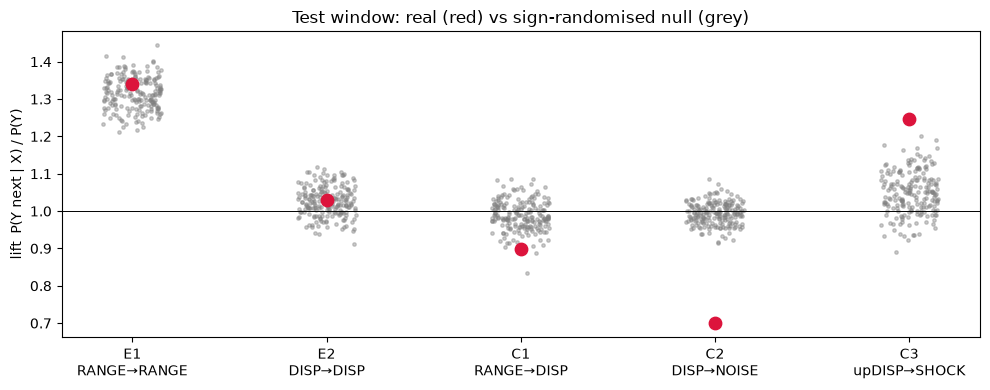

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
tests = [t for t, _, _ in rs.TESTS]
for k, t in enumerate(tests):
    ln = np.array([rs.pooled_lift([nb[j] for nb in NULL_BY_ASSET], ('test', t), null=True) for j in range(P.n_null)])
    ax.scatter(np.full(len(ln), k) + np.random.default_rng(k).uniform(-0.15, 0.15, len(ln)), ln, s=6, alpha=0.4, color='grey')
    ax.scatter([k], [rs.pooled_lift(REAL_BY_ASSET, ('test', t))], s=80, color='crimson', zorder=3)
ax.axhline(1, color='black', lw=0.7)
ax.set_xticks(range(len(tests)), [f'{t}\n{x}→{y}' for t, x, y in rs.TESTS])
ax.set_ylabel('lift  P(Y next | X) / P(Y)'); ax.set_title('Test window: real (red) vs sign-randomised null (grey)')
plt.tight_layout(); plt.show()

## 4. Save compact outputs

In [6]:
base.reset_index().to_csv(OUT / '01_label_base_rates.csv', index=False)
thr.to_csv(OUT / '01_thresholds.csv')
primary.to_csv(OUT / '01_primary.csv', index=False)
decision.to_csv(OUT / '01_decision.csv', index=False)
per_asset.to_csv(OUT / '01_per_asset.csv', index=False)
tm_real.to_csv(OUT / '01_transitions_real_test.csv'); tm_null.to_csv(OUT / '01_transitions_null_test.csv')
runs.to_csv(OUT / '01_run_lengths_test.csv')
manifest = {'registration': REG, 'assets_run': list(RES), 'synthetic': SYNTHETIC,
            'decision': decision.to_dict(orient='records'), 'run_utc': str(pd.Timestamp.now(tz='UTC'))}
(OUT / '01_manifest.json').write_text(json.dumps(manifest, indent=2, default=str), encoding='utf-8')
print('saved to', OUT, sorted(p.name for p in OUT.iterdir()))

saved to D:\Projects\deribit_market_data\notebooks\Regime_Structure\01 ['01_decision.csv', '01_label_base_rates.csv', '01_manifest.json', '01_per_asset.csv', '01_primary.csv', '01_run_lengths_test.csv', '01_thresholds.csv', '01_transitions_null_test.csv', '01_transitions_real_test.csv']
